In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import roc_auc_score, roc_curve

# Assert GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# Resolve Paths
cwd = Path.cwd()
PROJECT_ROOT = cwd if (cwd / "data").exists() else cwd.parent
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "toothbrush"
assert DATA_DIR.exists(), f"Directory not found: {DATA_DIR}"
print(f"Data directory verified at: {DATA_DIR}")

Running on device: cuda:0 (NVIDIA GeForce RTX 3050 Laptop GPU)
Data directory verified at: /home/asus/Defect  Detection/data/raw/toothbrush


In [2]:
# 1. Define standard ImageNet preprocessing pipeline
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Reusable MVTec Dataset class
class MVTecDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]
        label = self.labels[idx]
        
        with Image.open(path) as img:
            img = img.convert("RGB")
            if self.transform:
                img_tensor = self.transform(img)
                
        # Return tensor, ground-truth label, and filename for error tracking
        return img_tensor, label, path.name

# 3. Assemble training paths (Normal only)
train_paths = sorted(list((DATA_DIR / "train" / "good").glob("*.png")))
train_labels = [0] * len(train_paths)  # 0 = Normal

# 4. Assemble test paths (Normal + Defective)
test_good_paths = sorted(list((DATA_DIR / "test" / "good").glob("*.png")))
test_defective_paths = sorted(list((DATA_DIR / "test" / "defective").glob("*.png")))

test_paths = test_good_paths + test_defective_paths
test_labels = [0] * len(test_good_paths) + [1] * len(test_defective_paths)  # 1 = Defect

# 5. Build Datasets & DataLoaders
train_dataset = MVTecDataset(train_paths, train_labels, transform=transform)
test_dataset = MVTecDataset(test_paths, test_labels, transform=transform)

# Batch size of 16 keeps VRAM memory consumption < 500 MB
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(f"Train samples: {len(train_dataset)} (100% Normal [Label 0])")
print(f"Test samples : {len(test_dataset)} ({test_labels.count(0)} Normal [0], {test_labels.count(1)} Defective [1])")

Train samples: 60 (100% Normal [Label 0])
Test samples : 42 (12 Normal [0], 30 Defective [1])


In [3]:
# 1. Load pretrained ResNet-18
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

# 2. Strip the 1000-class classifier head (replace with Identity)
model.fc = nn.Identity()

# 3. Freeze all network parameters (Zero training, strictly inference)
model.eval()
for param in model.parameters():
    param.requires_grad = False

# Send model to our RTX 3050 GPU
model = model.to(device)

# 4. Feature extraction function with zero-memory footprint
def extract_features(model, dataloader, device):
    feature_chunks = []
    label_chunks = []
    name_chunks = []
    
    with torch.no_grad():
        for imgs, labels, names in dataloader:
            imgs = imgs.to(device)
            # Forward pass: shape [B, 512]
            feats = model(imgs)
            
            # Immediately offload to CPU NumPy array to keep GPU VRAM completely clean
            feature_chunks.append(feats.cpu().numpy())
            label_chunks.extend(labels.numpy())
            name_chunks.extend(names)
            
    features = np.concatenate(feature_chunks, axis=0)
    labels = np.array(label_chunks)
    return features, labels, name_chunks

print("Extracting features from Normal Train set...")
train_features, train_labels_arr, train_names = extract_features(model, train_loader, device)

print("Extracting features from Test set...")
test_features, test_labels_arr, test_names = extract_features(model, test_loader, device)

print("-" * 50)
print(f"Train Feature Matrix Shape: {train_features.shape} (60 images, 512 features each)")
print(f"Test Feature Matrix Shape : {test_features.shape} (42 images, 512 features each)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/asus/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100.0%


Extracting features from Normal Train set...
Extracting features from Test set...
--------------------------------------------------
Train Feature Matrix Shape: (60, 512) (60 images, 512 features each)
Test Feature Matrix Shape : (42, 512) (42 images, 512 features each)


=== Baseline Evaluation: Pretrained ResNet-18 Centroid Distance ===
Image-Level AUROC: 73.89%
------------------------------------------------------------
Normal Test Scores    -> Min: 7.60 | Mean: 9.00 | Max: 10.32
Defective Test Scores -> Min: 7.71 | Mean: 10.26 | Max: 15.58


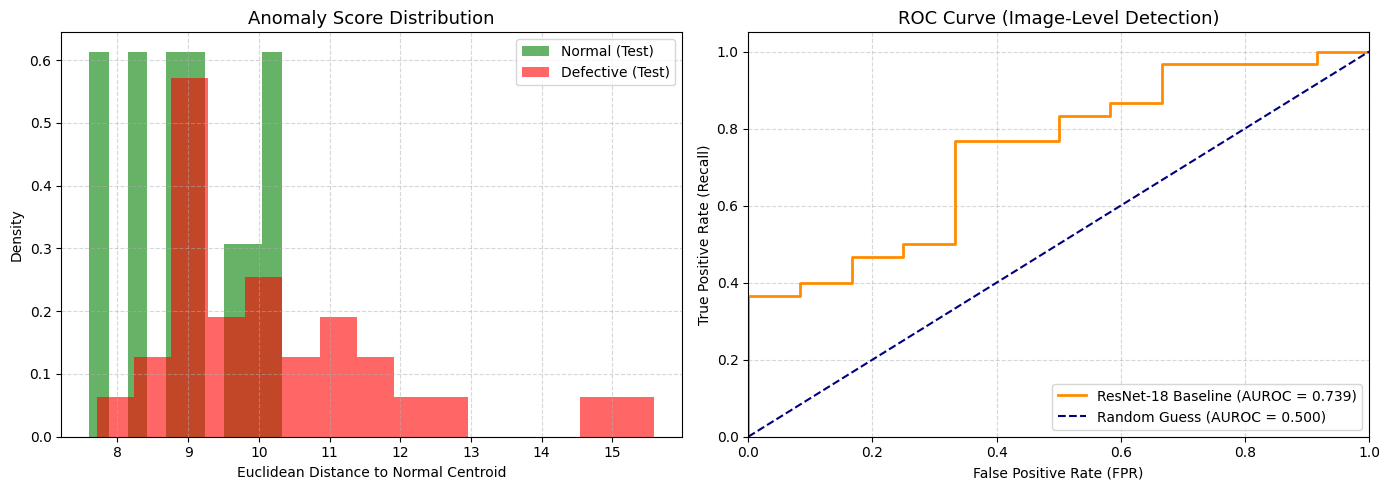

In [4]:
# 1. Compute the centroid (mean feature vector) of the 60 normal training images
normal_centroid = np.mean(train_features, axis=0)  # Shape: (512,)

# 2. Compute Euclidean distance anomaly scores for all test images
test_scores = np.linalg.norm(test_features - normal_centroid, axis=1)

# Also compute train scores for baseline comparison
train_scores = np.linalg.norm(train_features - normal_centroid, axis=1)

# 3. Calculate Image-Level AUROC
# test_labels_arr: 0 for Normal, 1 for Defective
auroc = roc_auc_score(test_labels_arr, test_scores)
fpr, tpr, thresholds = roc_curve(test_labels_arr, test_scores)

print("=== Baseline Evaluation: Pretrained ResNet-18 Centroid Distance ===")
print(f"Image-Level AUROC: {auroc * 100:.2f}%")
print("-" * 60)
print(f"Normal Test Scores    -> Min: {test_scores[test_labels_arr == 0].min():.2f} | "
      f"Mean: {test_scores[test_labels_arr == 0].mean():.2f} | "
      f"Max: {test_scores[test_labels_arr == 0].max():.2f}")
print(f"Defective Test Scores -> Min: {test_scores[test_labels_arr == 1].min():.2f} | "
      f"Mean: {test_scores[test_labels_arr == 1].mean():.2f} | "
      f"Max: {test_scores[test_labels_arr == 1].max():.2f}")

# 4. Visual Diagnostics: Score Distributions and ROC Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Anomaly Score Distribution
ax1.hist(test_scores[test_labels_arr == 0], bins=10, alpha=0.6, color="green", label="Normal (Test)", density=True)
ax1.hist(test_scores[test_labels_arr == 1], bins=15, alpha=0.6, color="red", label="Defective (Test)", density=True)
ax1.set_title("Anomaly Score Distribution", fontsize=13)
ax1.set_xlabel("Euclidean Distance to Normal Centroid")
ax1.set_ylabel("Density")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Receiver Operating Characteristic (ROC) Curve
ax2.plot(fpr, tpr, color="darkorange", lw=2, label=f"ResNet-18 Baseline (AUROC = {auroc:.3f})")
ax2.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Guess (AUROC = 0.500)")
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel("False Positive Rate (FPR)")
ax2.set_ylabel("True Positive Rate (Recall)")
ax2.set_title("ROC Curve (Image-Level Detection)", fontsize=13)
ax2.legend(loc="lower right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [5]:
# Fixed-Budget Factory Simulation: 1,000 items, 10% Review Capacity
np.random.seed(42)

SIM_BATCH_SIZE = 1000
REVIEW_BUDGET = 100  # 10% review capacity
DEFECT_PREVALENCE = 0.05  # 5% defect rate in production
N_DEFECTS = int(SIM_BATCH_SIZE * DEFECT_PREVALENCE)  # 50 defects
N_NORMALS = SIM_BATCH_SIZE - N_DEFECTS               # 950 normals
N_TRIALS = 100

# Separate normal and defective test scores
normal_test_scores = test_scores[test_labels_arr == 0]
defective_test_scores = test_scores[test_labels_arr == 1]

baseline_a_defects_caught = []
approach_b_defects_caught = []

for trial in range(N_TRIALS):
    # 1. Synthesize a factory shift of 1,000 parts by sampling from empirical distributions
    sampled_normals = np.random.choice(normal_test_scores, size=N_NORMALS, replace=True)
    sampled_defects = np.random.choice(defective_test_scores, size=N_DEFECTS, replace=True)
    
    batch_scores = np.concatenate([sampled_normals, sampled_defects])
    # 0 = Normal, 1 = Defect
    batch_true_labels = np.concatenate([np.zeros(N_NORMALS), np.ones(N_DEFECTS)])
    
    # 2. Baseline A: Random Sampling of 100 items
    random_indices = np.random.choice(SIM_BATCH_SIZE, size=REVIEW_BUDGET, replace=False)
    defects_caught_a = int(np.sum(batch_true_labels[random_indices] == 1))
    baseline_a_defects_caught.append(defects_caught_a)
    
    # 3. Approach B: AI-Assisted Prioritization (Top 100 highest anomaly scores)
    # Argsort sorts ascending; take the last 100 for highest scores
    top_100_indices = np.argsort(batch_scores)[-REVIEW_BUDGET:]
    defects_caught_b = int(np.sum(batch_true_labels[top_100_indices] == 1))
    approach_b_defects_caught.append(defects_caught_b)

# Aggregate statistics
mean_a = np.mean(baseline_a_defects_caught)
std_a = np.std(baseline_a_defects_caught)
recall_a = (mean_a / N_DEFECTS) * 100

mean_b = np.mean(approach_b_defects_caught)
std_b = np.std(approach_b_defects_caught)
recall_b = (mean_b / N_DEFECTS) * 100

improvement = (mean_b / mean_a) if mean_a > 0 else 0

print("=" * 65)
print(f"FACTORY SIMULATION RESULTS ({N_TRIALS} Monte Carlo Trials)")
print(f"Batch Size: {SIM_BATCH_SIZE} items | True Defects: {N_DEFECTS} (5%) | Review Budget: {REVIEW_BUDGET} items (10%)")
print("=" * 65)
print(f"Baseline A (Random Sampling)   : Caught {mean_a:.1f} ± {std_a:.1f} defects | Recall: {recall_a:.1f}%")
print(f"Approach B (AI Prioritization) : Caught {mean_b:.1f} ± {std_b:.1f} defects | Recall: {recall_b:.1f}%")
print("-" * 65)
print(f"Defect Capture Multiplier      : {improvement:.2f}x more defects caught!")
print(f"Reduction in Missed Defects    : From {N_DEFECTS - mean_a:.1f} down to {N_DEFECTS - mean_b:.1f}")
print("=" * 65)

FACTORY SIMULATION RESULTS (100 Monte Carlo Trials)
Batch Size: 1000 items | True Defects: 50 (5%) | Review Budget: 100 items (10%)
Baseline A (Random Sampling)   : Caught 5.0 ± 2.3 defects | Recall: 10.1%
Approach B (AI Prioritization) : Caught 19.4 ± 3.3 defects | Recall: 38.9%
-----------------------------------------------------------------
Defect Capture Multiplier      : 3.85x more defects caught!
Reduction in Missed Defects    : From 45.0 down to 30.6


In [6]:
# Business Cost Simulation and Sensitivity Analysis

# 1. Base Assumptions (Hypothetical operational parameters)
C_REVIEW = 0.50       # $0.50 labor cost per human inspection
C_MISSED_BASE = 30.00 # $30.00 estimated cost per escaped defect

missed_a = N_DEFECTS - mean_a  # ~45.0
missed_b = N_DEFECTS - mean_b  # ~30.6

cost_review = REVIEW_BUDGET * C_REVIEW  # 100 * $0.50 = $50.00
cost_missed_a = missed_a * C_MISSED_BASE
cost_missed_b = missed_b * C_MISSED_BASE

total_cost_a = cost_review + cost_missed_a
total_cost_b = cost_review + cost_missed_b
savings = total_cost_a - total_cost_b
savings_pct = (savings / total_cost_a) * 100

print("=" * 65)
print(f"BUSINESS COST MODEL (Per 1,000 Inspected Units)")
print(f"Assumptions: Review Cost = ${C_REVIEW:.2f}/item | Escaped Defect Cost = ${C_MISSED_BASE:.2f}/item")
print("=" * 65)
print(f"Baseline A (Random Sampling)   : ${total_cost_a:.2f} (Review: ${cost_review:.2f} + Escapes: ${cost_missed_a:.2f})")
print(f"Approach B (AI Prioritization) : ${total_cost_b:.2f} (Review: ${cost_review:.2f} + Escapes: ${cost_missed_b:.2f})")
print("-" * 65)
print(f"Expected Net Savings per Batch : ${savings:.2f} ({savings_pct:.1f}% reduction in quality costs)")
print("=" * 65)

# 2. Sensitivity Analysis: How savings scale across different defect penalty costs
cost_scenarios = [10.0, 20.0, 30.0, 50.0, 100.0]
sensitivity_data = []

for c_miss in cost_scenarios:
    cost_a = cost_review + (missed_a * c_miss)
    cost_b = cost_review + (missed_b * c_miss)
    net_save = cost_a - cost_b
    pct_save = (net_save / cost_a) * 100
    sensitivity_data.append({
        "Escaped Defect Cost ($)": f"${c_miss:.2f}",
        "Baseline A Total Cost": f"${cost_a:.2f}",
        "Approach B Total Cost": f"${cost_b:.2f}",
        "Net Savings ($)": f"${net_save:.2f}",
        "Cost Reduction (%)": f"{pct_save:.1f}%"
    })

df_sensitivity = pd.DataFrame(sensitivity_data)
print("\n=== Sensitivity Analysis Across Defect Cost Scenarios ===")
display(df_sensitivity)

BUSINESS COST MODEL (Per 1,000 Inspected Units)
Assumptions: Review Cost = $0.50/item | Escaped Defect Cost = $30.00/item
Baseline A (Random Sampling)   : $1398.50 (Review: $50.00 + Escapes: $1348.50)
Approach B (AI Prioritization) : $966.50 (Review: $50.00 + Escapes: $916.50)
-----------------------------------------------------------------
Expected Net Savings per Batch : $432.00 (30.9% reduction in quality costs)

=== Sensitivity Analysis Across Defect Cost Scenarios ===


,Escaped Defect Cost ($),Baseline A Total Cost,Approach B Total Cost,Net Savings ($),Cost Reduction (%)
0,$10.00,$499.50,$355.50,$144.00,28.8%
1,$20.00,$949.00,$661.00,$288.00,30.3%
2,$30.00,$1398.50,$966.50,$432.00,30.9%
3,$50.00,$2297.50,$1577.50,$720.00,31.3%
4,$100.00,$4545.00,$3105.00,$1440.00,31.7%
